Генерация временного ряда с выбором варинта тренда, сезонности

Введите количество точек: 1000
Выберите сезонность: none; one; two: one
Выберите тренд: none; fast_up; slow_up; fast_down; slow_downslow_down


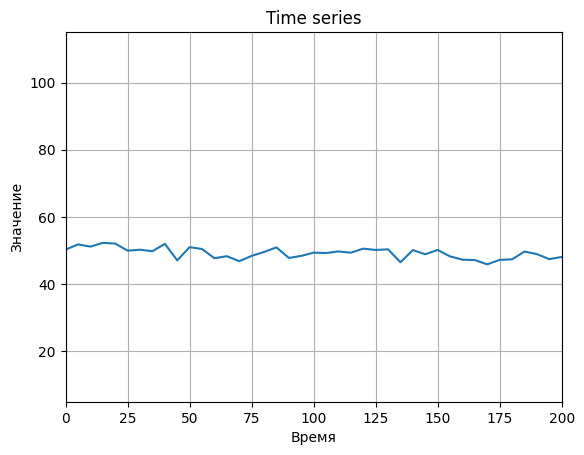

In [ ]:
#Time series contains 3 addends: random components, seasonality, trend

import numpy as np
import matplotlib.pyplot as plt

n = int(input("Введите количество точек: "))
point_index = np.arange(n) # создали массив из n-заданных точек
t = point_index * 5 #обеспечивает интервал между точками в 5 минут

variance = np.linspace(1,25,len(t))
#variance = 4 #const дисперсия
#variance = np.linspace(25,1,len(t)) #убывающая дисперсия

random_component = np.random.normal(loc=0,scale=np.sqrt(variance),size=len(t))

period_1 = 100
period_2 = 250

seasonality_options = {
    "none": np.zeros(len(t)),
    "one": np.sin(2 * np.pi * t / period_1),
    "two": (
        np.sin(2 * np.pi * t / period_1)
        + np.sin(2 * np.pi * t / period_2)
    )
}
choice = input("Выберите сезонность: none; one; two: ").strip().lower()
seasonality = seasonality_options[choice]

#omega = 2 * np.pi / period
#seasonality = np.sin(omega * t)

trend_coefficient_options = {
    "none": 0,
    "fast_up": 0.5,
    "slow_up": 0.01,
    "fast_down": -0.5,
    "slow_down": -0.01
    }
choice = input("Выберите тренд: none; fast_up; slow_up; fast_down; slow_down").strip().lower()
trend_coefficient_value = trend_coefficient_options[choice]

a = 50
trend = a + trend_coefficient_value * t

y = random_component + seasonality + trend

res_array = np.column_stack((t,y))

plt.plot(t,y)
plt.xlabel("Время")
plt.ylabel("Значение")
plt.title("Time series")
plt.grid(True)
plt.xlim(0, 200) #показывает только первые 200 шагов из 5000
plt.ylim(5, 115)
plt.show ()



### Генерация временного ряда формата "дата-значение"

Введите количество точек: 500
Выберите волатильность: const; grow; decay: decay
Выберите сезонность: none; one; two: one
Выберите тренд: none; fast_up; slow_up; fast_down; slow_downslow_down
Результат сохранён в time_series.csv


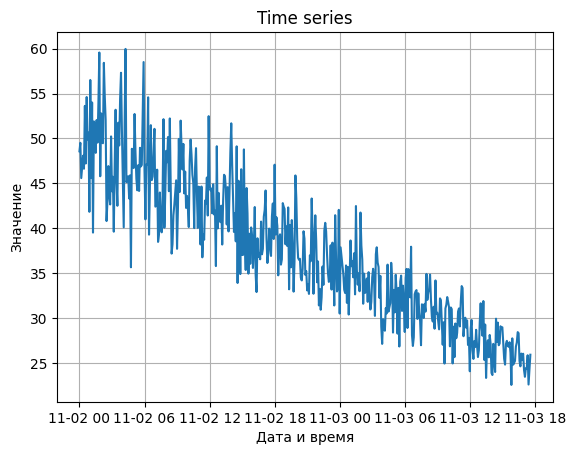

In [ ]:
from datetime import datetime, timedelta
import matplotlib.dates as mdates
import numpy as np
import matplotlib.pyplot as plt

n = int(input("Введите количество точек: "))
start = datetime.now().replace(hour=0, minute=0, second=0, microsecond=0)

dates = [start + timedelta(minutes=5 * i) for i in range(n)]

t = np.arange(n) * 5 # Числовое время в минутах для вычисления сезонности и тренда

variance_options = {
    "const": 4,
    "grow": np.linspace(1,25,len(t)),
    "decay": np.linspace(25,1,len(t))
}
choice_variance = input("Выберите волатильность: const; grow; decay: ").strip().lower()
variance = variance_options[choice_variance]

random_component = np.random.normal(loc=0,scale=np.sqrt(variance),size=len(t))

period_1 = 100
period_2 = 250

seasonality_options = {
    "none": np.zeros(len(t)),
    "one": np.sin(2 * np.pi * t / period_1),
    "two": (
        np.sin(2 * np.pi * t / period_1)
        + np.sin(2 * np.pi * t / period_2)
    )
}
choice = input("Выберите сезонность: none; one; two: ").strip().lower()
seasonality = seasonality_options[choice]

#omega = 2 * np.pi / period
#seasonality = np.sin(omega * t)

trend_coefficient_options = {
    "none": 0,
    "fast_up": 0.5,
    "slow_up": 0.01,
    "fast_down": -0.5,
    "slow_down": -0.01
    }
choice = input("Выберите тренд: none; fast_up; slow_up; fast_down; slow_down").strip().lower()
trend_coefficient_value = trend_coefficient_options[choice]

a = 50
trend = a + trend_coefficient_value * t # коэффициент — изменение за минуту

y = random_component + seasonality + trend

import csv

filename = "time_series.csv"

with open(filename, "w", newline="", encoding="utf-8") as file:
  writer = csv.writer(file)
  writer.writerow(["datetime", "value"]) # заголовки столбцов

  for date, value in zip(dates,y):
    writer.writerow([
        date.strftime("%Y-%m-%d %H:%M:%S"),
        value
    ])

print(f"Результат сохранён в {filename}")

res_array = np.column_stack((dates,y))

plt.plot(dates, y)
plt.xlabel("Дата и время")
plt.ylabel("Значение")
plt.title("Time series")
plt.grid(True)
plt.show ()
